# **ЛАБОРАТОРНА РОБОТА 8**
## **Prac 08.1**

In [28]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Dense, Flatten, Input, MaxPooling2D, Dropout
from tensorflow.keras import Model
from collections import Counter

from time import time

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [12, 5]

from numpy.random import seed
from tensorflow.random import set_seed
seed_value = 1234578790
seed(seed_value)
set_seed(seed_value)

## **1. Аналіз та підготовка даних**

In [29]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

classes = {0: 'plane', 1: 'car', 2: 'bird', 3: 'cat', 4: 'deer', 5: 'dog', 6: 'frog', 7: 'horse', 8: 'ship', 9: 'truck'}

num_classes = len(classes)
size = x_train.shape[1]

C:\Users\BOS\AppData\Local\Temp\ipykernel_5636\1336104536.py:6: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  plt.title(classes[int(y_train[idx])])


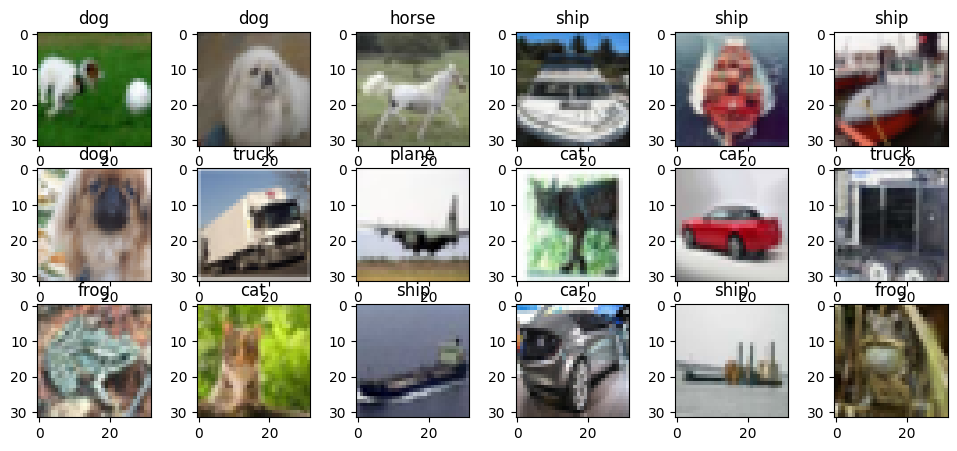

In [30]:
for i in range(18):
    
    plt.subplot(3, 6, i + 1)
    idx = np.random.randint(len(x_train))
    plt.imshow(x_train[idx, ...])
    plt.title(classes[int(y_train[idx])])

plt.show()

### Гістограма класів

In [31]:
class_counts = Counter(y_train.flatten())

print("Class histogram:")

for class_id, count in class_counts.items():
    print(classes[class_id], count)

Class histogram:
frog 5000
truck 5000
deer 5000
car 5000
bird 5000
horse 5000
ship 5000
cat 5000
dog 5000
plane 5000


### Нормалізація та One-hot кодування

In [32]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = tf.keras.utils.to_categorical(y_train, num_classes)
y_test = tf.keras.utils.to_categorical(y_test, num_classes)

print('Train set:   ', len(y_train), 'samples')
print('Test set:    ', len(y_test), 'samples')
print('Sample dims: ', x_train.shape) 

Train set:    50000 samples
Test set:     10000 samples
Sample dims:  (50000, 32, 32, 3)


## **2. Побудова класифікатора**

In [33]:
inputs = Input(shape=(size, size, 3))

net = Conv2D(16, kernel_size=(3, 3), activation="relu")(inputs)
net = MaxPooling2D(pool_size=(2, 2))(net)

net = Conv2D(32, kernel_size=(3, 3), activation="relu")(net)
net = MaxPooling2D(pool_size=(2, 2))(net)

net = Flatten()(net)
outputs = Dense(num_classes, activation="softmax")(net)

model = Model(inputs, outputs)

model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │        11,530 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,618 (64.91 KB)

 Trainable params: 16,618 (64.91 KB)

 Non-trainable params: 0 (0.00 B)

### Навчання

In [34]:
epochs = 25
batch_size = 128

model.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

history = model.fit(
    x_train,
    y_train,
    batch_size=batch_size,
    epochs=epochs,
    validation_split=0.1
)

Epoch 1/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 40ms/step - accuracy: 0.3861 - loss: 1.7213 - val_accuracy: 0.4644 - val_loss: 1.5382
Epoch 2/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 51ms/step - accuracy: 0.4957 - loss: 1.4267 - val_accuracy: 0.5002 - val_loss: 1.4297
Epoch 3/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 13s 37ms/step - accuracy: 0.5384 - loss: 1.3110 - val_accuracy: 0.5482 - val_loss: 1.2953
Epoch 4/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 32ms/step - accuracy: 0.5677 - loss: 1.2337 - val_accuracy: 0.5702 - val_loss: 1.2255
Epoch 5/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 29ms/step - accuracy: 0.5904 - loss: 1.1760 - val_accuracy: 0.5882 - val_loss: 1.1814
Epoch 6/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 10s 28ms/step - accuracy: 0.6066 - loss: 1.1314 - val_accuracy: 0.6016 - val_loss: 1.1432
Epoch 7/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.6196 - loss: 1.0955 - val_accuracy: 0.6146 - val_loss: 1.1110
Epoch 8/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 12s 35ms/step - accuracy: 0.6298 - loss: 1.0659 - 

### Графіків функції втрат та точності  

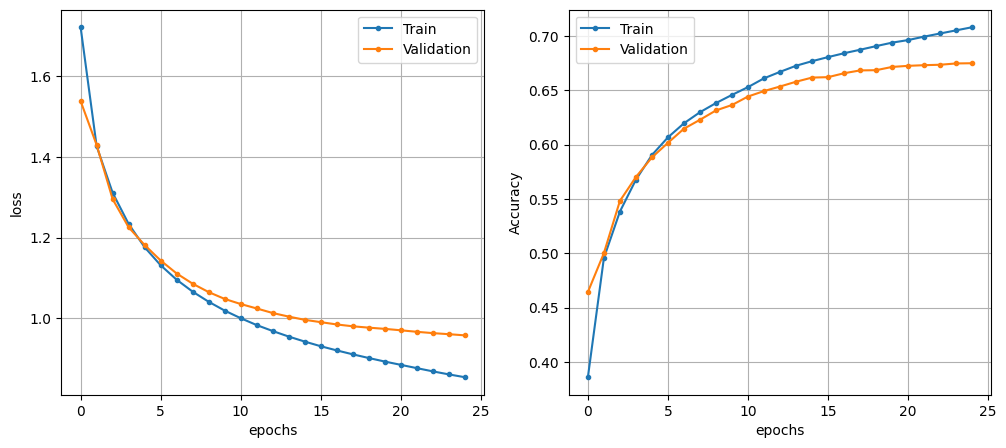

Train Acc      0.7079111337661743
Validation Acc 0.6747999787330627


In [35]:
h = history.history
epochs = range(len(h['loss']))

plt.subplot(121)
plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')

plt.grid(True)
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend(['Train', 'Validation'])

plt.subplot(122)
plt.plot(epochs, h['accuracy'], '.-', epochs, h['val_accuracy'], '.-')

plt.grid(True)
plt.xlabel('epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

plt.show()

print('Train Acc     ', h['accuracy'][-1])
print('Validation Acc', h['val_accuracy'][-1])

## **3. Оцінювання**

In [36]:
y_true = np.argmax(y_test, axis=1)

y_pred = np.argmax(model.predict(x_test), axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step


In [37]:
for class_id, class_name in classes.items():

    mask = y_true == class_id
    acc = np.mean(y_pred[mask] == class_id)

    print(class_name, acc)

plane 0.716
car 0.741
bird 0.577
cat 0.457
deer 0.669
dog 0.58
frog 0.752
horse 0.681
ship 0.726
truck 0.758


In [38]:
ev = model.evaluate(x_test, y_test)

print('Test loss  ', ev[0])
print('Test accuracy', ev[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - accuracy: 0.6657 - loss: 0.9818
Test loss   0.9818459749221802
Test accuracy 0.6657000184059143


### Випадкові приклади

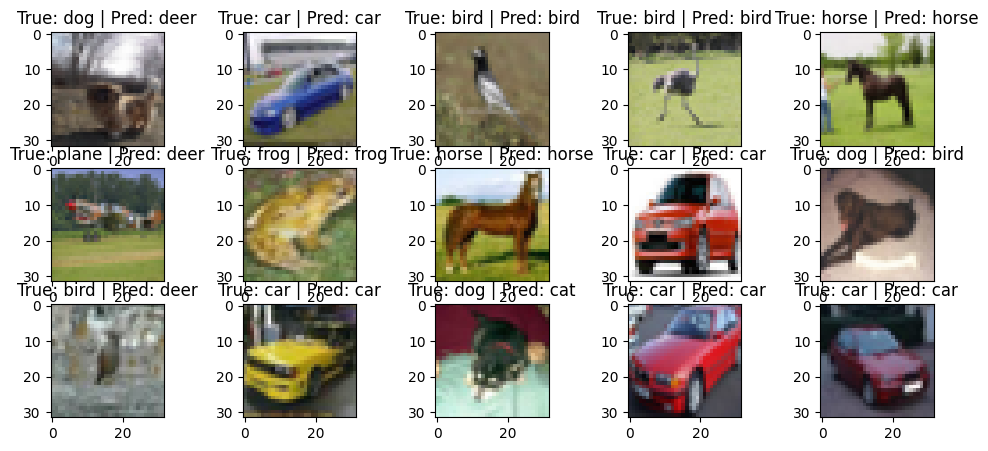

In [ ]:
for ii in range(15):

    idx = np.random.randint(len(x_test))
    plt.subplot(3, 5, ii + 1)
    plt.imshow( x_test[idx, ...])
    plt.title('True: ' + str(classes[y_true[idx]]) + ' | Pred: ' + str(classes[y_pred[idx]]))

plt.tight_layout()
plt.show()

## **3. Покращення точності**

In [40]:
inputs = Input(shape=(size, size, 3))

net = Conv2D(16, kernel_size=(3, 3), activation="relu")(inputs)
net = MaxPooling2D(pool_size=(2, 2))(net)

net = Conv2D(32, kernel_size=(3, 3), activation="relu")(net)
net = MaxPooling2D(pool_size=(2, 2))(net)

net = Flatten()(net)
net = Dropout(0.3)(net)

net = Dense(128, activation="relu")(net)
net = Dropout(0.3)(net)

outputs = Dense(num_classes, activation="softmax")(net)

model_new = Model(inputs, outputs)

model_new.summary()

Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 30, 30, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 15, 15, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 13, 13, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 6, 6, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_4 (Flatten)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 1152)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 153,962 (601.41 KB)

 Trainable params: 153,962 (601.41 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
model_new.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])

history = model_new.fit(
    x_train, y_train,
    batch_size=128,
    epochs=25,
    validation_split=0.1
)

Epoch 1/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 20s 45ms/step - accuracy: 0.3740 - loss: 1.7119 - val_accuracy: 0.4898 - val_loss: 1.4309
Epoch 2/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.4997 - loss: 1.4019 - val_accuracy: 0.5378 - val_loss: 1.3016
Epoch 3/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 18s 51ms/step - accuracy: 0.5449 - loss: 1.2821 - val_accuracy: 0.5844 - val_loss: 1.1803
Epoch 4/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 55ms/step - accuracy: 0.5705 - loss: 1.2087 - val_accuracy: 0.6212 - val_loss: 1.0942
Epoch 5/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 39ms/step - accuracy: 0.5909 - loss: 1.1578 - val_accuracy: 0.6308 - val_loss: 1.0638
Epoch 6/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 15s 41ms/step - accuracy: 0.6094 - loss: 1.1092 - val_accuracy: 0.6512 - val_loss: 1.0162
Epoch 7/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 14s 40ms/step - accuracy: 0.6216 - loss: 1.0686 - val_accuracy: 0.6572 - val_loss: 0.9996
Epoch 8/25
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 45ms/step - accuracy: 0.6319 - loss: 1.0421 - 

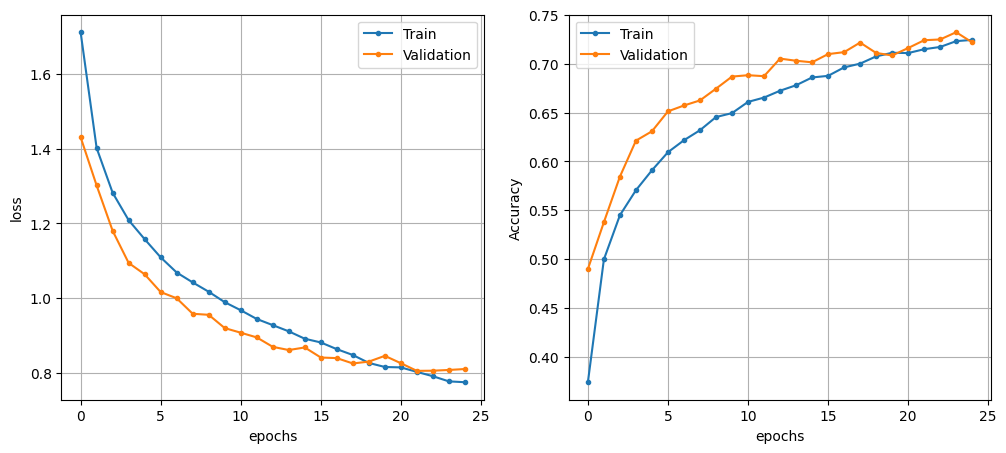

Train Acc      0.7243555784225464
Validation Acc 0.7218000292778015


In [42]:
h = history.history
epochs = range(len(h['loss']))

plt.subplot(121)
plt.plot(epochs, h['loss'], '.-', epochs, h['val_loss'], '.-')

plt.grid(True)
plt.xlabel('epochs')
plt.ylabel('loss')
plt.legend(['Train', 'Validation'])

plt.subplot(122)
plt.plot(epochs, h['accuracy'], '.-', epochs, h['val_accuracy'], '.-')

plt.grid(True)
plt.xlabel('epochs')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Validation'])

plt.show()

print('Train Acc     ', h['accuracy'][-1])
print('Validation Acc', h['val_accuracy'][-1])

In [43]:
ev = model_new.evaluate(x_test, y_test)

print("Test loss:", ev[0])
print("Test accuracy:", ev[1])

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.7150 - loss: 0.8333
Test loss: 0.8332921862602234
Test accuracy: 0.7149999737739563
